# Lasso on the baseline feature set

In [1]:
"""Same rows, columns and 80/20 split as 01_baseline (read from config.MODEL_MATRIX_PATH). Each column is standardized,
then Lasso shrinks coefficients and sets the unhelpful ones to exactly 0. The penalty (alpha) is chosen by 5-fold CV on
the 80%; the 20% test set is scored once, with the chosen alpha refit on the full 80%."""
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, os.path.abspath("../src"))
import config

warnings.filterwarnings("ignore", category=ConvergenceWarning)
RED, ACCENT, GRAY = "#990000", "#C44545", "#C9C9C9"

## Load the design matrix

In [2]:
df_matrix = pd.read_csv(config.MODEL_MATRIX_PATH)
df_ols = pd.read_csv(os.path.join(os.path.dirname(config.MODEL_MATRIX_PATH), "ols_results.csv"))
feature_cols = [col for col in df_matrix.columns if col not in ["id", "channel_id", "views", "likes", "split"]]
df_train = df_matrix[df_matrix["split"] == "train"]
df_test = df_matrix[df_matrix["split"] == "test"]
targets = {
    "views": df_matrix["views"],
    "log_views": np.log1p(df_matrix["views"]),
    "likes": df_matrix["likes"],
    "log_likes": np.log1p(df_matrix["likes"]),
}
print(f"{len(feature_cols)} columns | train {len(df_train)} | test {len(df_test)}")

372 columns | train 580 | test 146


## Choose alpha by 5-fold CV on the 80%

In [3]:
"""For each target, alphas run from alpha_max (every coefficient is 0) down to alpha_max / 1000. The scaler is inside
the pipeline, so each CV fold standardizes with its own training rows only."""
def score_rows(actual, predicted):
    return {"R2": r2_score(actual, predicted), "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "MAE": mean_absolute_error(actual, predicted)}


folds = list(KFold(n_splits=5, shuffle=True, random_state=42).split(df_train))
cv_curves = {}
best_alphas = {}
for target_name, target in targets.items():
    y_train = target.loc[df_train.index]
    x_scaled = StandardScaler().fit_transform(df_train[feature_cols])
    alpha_max = np.max(np.abs(x_scaled.T @ (y_train - y_train.mean()))) / len(y_train)
    alphas = alpha_max * np.logspace(0, -3, 25)
    curve_rows = []
    for alpha in alphas:
        fold_r2 = []
        for fold_fit_index, fold_score_index in folds:
            model = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=20000))
            model.fit(df_train[feature_cols].iloc[fold_fit_index], y_train.iloc[fold_fit_index])
            fold_r2.append(r2_score(y_train.iloc[fold_score_index], model.predict(df_train[feature_cols].iloc[fold_score_index])))
        curve_rows.append({"alpha": alpha, "cv_R2_mean": np.mean(fold_r2), "cv_R2_sd": np.std(fold_r2)})
    cv_curves[target_name] = pd.DataFrame(curve_rows)
    best_alphas[target_name] = cv_curves[target_name].loc[cv_curves[target_name]["cv_R2_mean"].idxmax(), "alpha"]
pd.Series(best_alphas, name="best alpha")

views        3.027540e+06
log_views    5.683180e-02
likes        3.468689e+04
log_likes    5.498704e-02
Name: best alpha, dtype: float64

## CV R² along the alpha path

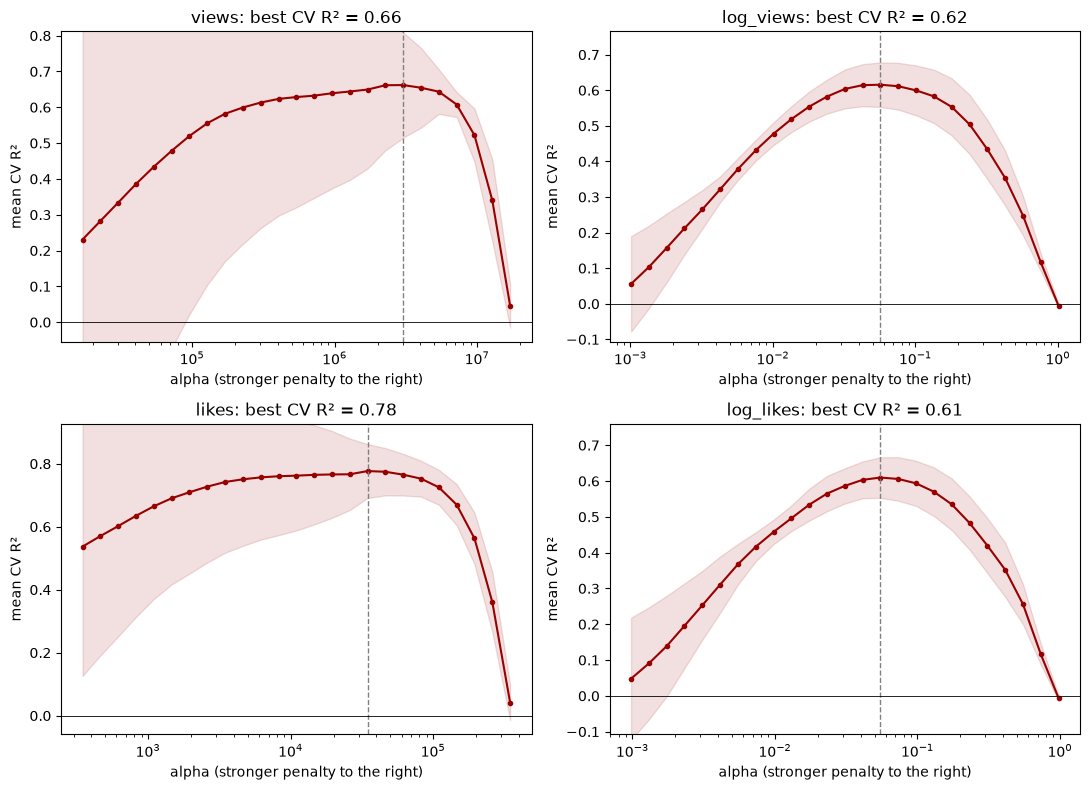

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (target_name, df_curve) in zip(axes.ravel(), cv_curves.items()):
    ax.plot(df_curve["alpha"], df_curve["cv_R2_mean"], color=RED, marker="o", markersize=3)
    ax.fill_between(df_curve["alpha"], df_curve["cv_R2_mean"] - df_curve["cv_R2_sd"], df_curve["cv_R2_mean"] + df_curve["cv_R2_sd"], color=RED, alpha=0.12)
    ax.axvline(best_alphas[target_name], color="gray", linestyle="--", linewidth=1)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_xscale("log")
    ax.set_ylim(max(df_curve["cv_R2_mean"].min() - 0.1, -1), min(df_curve["cv_R2_mean"].max() + 0.15, 1))
    ax.set_title(f"{target_name}: best CV R² = {df_curve['cv_R2_mean'].max():.2f}")
    ax.set_xlabel("alpha (stronger penalty to the right)")
    ax.set_ylabel("mean CV R²")
plt.tight_layout()
plt.show()

## Refit with the chosen alpha: train / CV / test

In [5]:
"""CV here is the score at the alpha that CV itself picked, so it is slightly optimistic; the test score is the honest one."""
df_results_rows = []
lasso_models = {}
for target_name, target in targets.items():
    y_train = target.loc[df_train.index]
    y_test = target.loc[df_test.index]
    model = make_pipeline(StandardScaler(), Lasso(alpha=best_alphas[target_name], max_iter=50000)).fit(df_train[feature_cols], y_train)
    lasso_models[target_name] = model
    df_results_rows.append({"target": target_name, "split": "train", **score_rows(y_train, model.predict(df_train[feature_cols]))})

    fold_scores = []
    for fold_fit_index, fold_score_index in folds:
        fold_model = make_pipeline(StandardScaler(), Lasso(alpha=best_alphas[target_name], max_iter=50000))
        fold_model.fit(df_train[feature_cols].iloc[fold_fit_index], y_train.iloc[fold_fit_index])
        fold_scores.append(score_rows(y_train.iloc[fold_score_index], fold_model.predict(df_train[feature_cols].iloc[fold_score_index])))
    df_folds = pd.DataFrame(fold_scores)
    df_results_rows.append({"target": target_name, "split": "cv5_mean", **df_folds.mean().to_dict()})
    df_results_rows.append({"target": target_name, "split": "cv5_sd", **df_folds.std().to_dict()})
    df_results_rows.append({"target": target_name, "split": "test", **score_rows(y_test, model.predict(df_test[feature_cols]))})

df_lasso = pd.DataFrame(df_results_rows)
df_lasso["n_features_kept"] = df_lasso["target"].map({target_name: int((np.abs(model[-1].coef_) > 1e-8).sum()) for target_name, model in lasso_models.items()})
df_lasso.pivot_table(index="target", columns="split", values=["R2", "RMSE", "MAE"], sort=False).round(3)

R2                                RMSE               \
split      train cv5_mean cv5_sd   test        train     cv5_mean   
target                                                              
views      0.754    0.662  0.164 -0.847  9617579.148  9676047.408   
log_views  0.759    0.616  0.070  0.661        1.165        1.461   
likes      0.814    0.777  0.096 -1.176   165952.443   164929.920   
log_likes  0.757    0.610  0.063  0.638        1.199        1.511   

                                              MAE                           \
split           cv5_sd          test        train     cv5_mean      cv5_sd   
target                                                                       
views      2927239.463  1.763889e+07  3668298.382  3747736.414  516082.623   
log_views        0.128  1.407000e+00        0.921        1.172       0.096   
likes        49528.700  3.385025e+05    67518.627    68303.855    6398.348   
log_likes        0.131  1.483000e+00        0.930        1.188       0.087   

                        
split             test  
target                  
views      5635007.893  
log_views        1.111  
likes       112018.220  
log_likes        1.174

## OLS vs Lasso

In [6]:
def metric_value(df, target_name, split):
    return float(df.loc[(df["target"] == target_name) & (df["split"] == split), "R2"].iloc[0])


df_compare = pd.concat([df_ols.assign(model="OLS"), df_lasso.drop(columns="n_features_kept").assign(model="Lasso")])
df_compare = df_compare[df_compare["split"].isin(["train", "test", "cv5_mean"])]
df_compare.pivot_table(index=["target", "model"], columns="split", values=["R2", "MAE"], sort=False)[[("R2", "train"), ("R2", "test"), ("R2", "cv5_mean"), ("MAE", "train"), ("MAE", "test"), ("MAE", "cv5_mean")]].round(3)

R2                          MAE                \
split            train   test cv5_mean        train          test   
target    model                                                     
views     OLS    0.944 -3.011   -0.497  3102223.580  1.307368e+07   
          Lasso  0.754 -0.847    0.662  3668298.382  5.635008e+06   
log_views OLS    0.892  0.190   -0.255        0.613  1.762000e+00   
          Lasso  0.759  0.661    0.616        0.921  1.111000e+00   
likes     OLS    0.956 -3.716   -1.051    55835.253  2.440547e+05   
          Lasso  0.814 -1.176    0.777    67518.627  1.120182e+05   
log_likes OLS    0.890  0.136   -0.195        0.620  1.839000e+00   
          Lasso  0.757  0.638    0.610        0.930  1.174000e+00   

                               
split                cv5_mean  
target    model                
views     OLS    1.118928e+07  
          Lasso  3.747736e+06  
log_views OLS    2.047000e+00  
          Lasso  1.172000e+00  
likes     OLS    2.025705e+05  
          Lasso  6.830385e+04  
log_likes OLS    2.073000e+00  
          Lasso  1.188000e+00

## Overfitting along the Lasso path: train vs test MAE

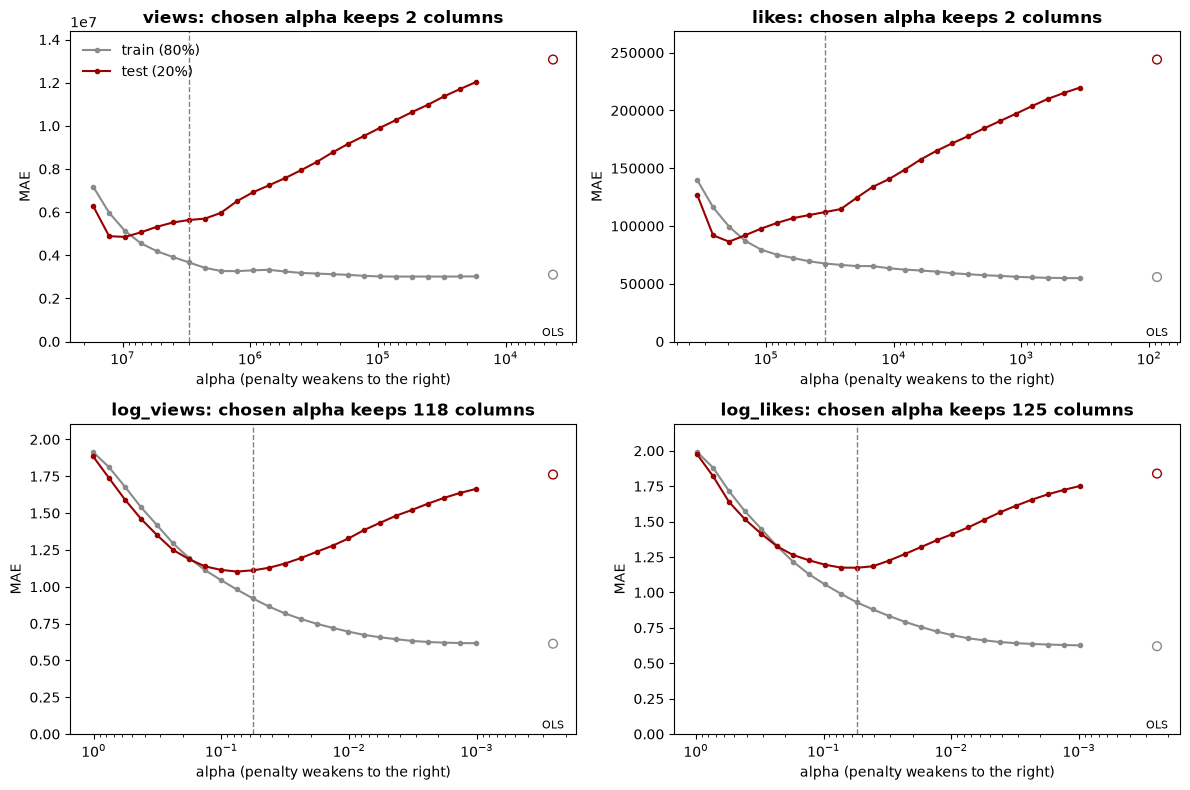

In [7]:
"""Refit on the 80% at every alpha. Left = strong penalty (few columns), right = weak penalty (close to plain OLS,
shown as the open markers at the far right). Dashed line = the alpha chosen by 5-fold CV. Overfitting shows as train
MAE falling while test MAE turns back up."""
df_path_rows = []
for target_name, target in targets.items():
    y_train = target.loc[df_train.index]
    y_test = target.loc[df_test.index]
    for alpha in cv_curves[target_name]["alpha"]:
        model = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=20000)).fit(df_train[feature_cols], y_train)
        pred_train = model.predict(df_train[feature_cols])
        pred_test = model.predict(df_test[feature_cols])
        df_path_rows.append({"target": target_name, "alpha": alpha, "n_kept": int((np.abs(model[-1].coef_) > 1e-8).sum()),
                             "train_MAE": mean_absolute_error(y_train, pred_train), "test_MAE": mean_absolute_error(y_test, pred_test),
                             "train_R2": r2_score(y_train, pred_train), "test_R2": r2_score(y_test, pred_test)})
df_path = pd.DataFrame(df_path_rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, target_name in zip(axes.ravel(), ["views", "likes", "log_views", "log_likes"]):
    df_target = df_path[df_path["target"] == target_name]
    ols_x = df_target["alpha"].min() / 4
    ols_train_mae = df_ols.loc[(df_ols["target"] == target_name) & (df_ols["split"] == "train"), "MAE"].iloc[0]
    ols_test_mae = df_ols.loc[(df_ols["target"] == target_name) & (df_ols["split"] == "test"), "MAE"].iloc[0]
    ax.plot(df_target["alpha"], df_target["train_MAE"], color="#8A8A8A", marker="o", markersize=3, label="train (80%)")
    ax.plot(df_target["alpha"], df_target["test_MAE"], color=RED, marker="o", markersize=3, label="test (20%)")
    ax.scatter([ols_x, ols_x], [ols_train_mae, ols_test_mae], facecolors="none", edgecolors=["#8A8A8A", RED], s=40)
    ax.annotate("OLS", (ols_x, 0), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8)
    ax.axvline(best_alphas[target_name], color="gray", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.invert_xaxis()
    ax.set_ylim(0, max(df_target[["train_MAE", "test_MAE"]].to_numpy().max(), ols_test_mae) * 1.1)
    ax.set_xlabel("alpha (penalty weakens to the right)")
    ax.set_ylabel("MAE")
    ax.set_title(f"{target_name}: chosen alpha keeps {df_lasso.loc[df_lasso['target'] == target_name, 'n_features_kept'].iloc[0]} columns", fontweight="bold")
axes[0, 0].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

## What Lasso kept: log(views)

log_views: kept 118 of 372 columns


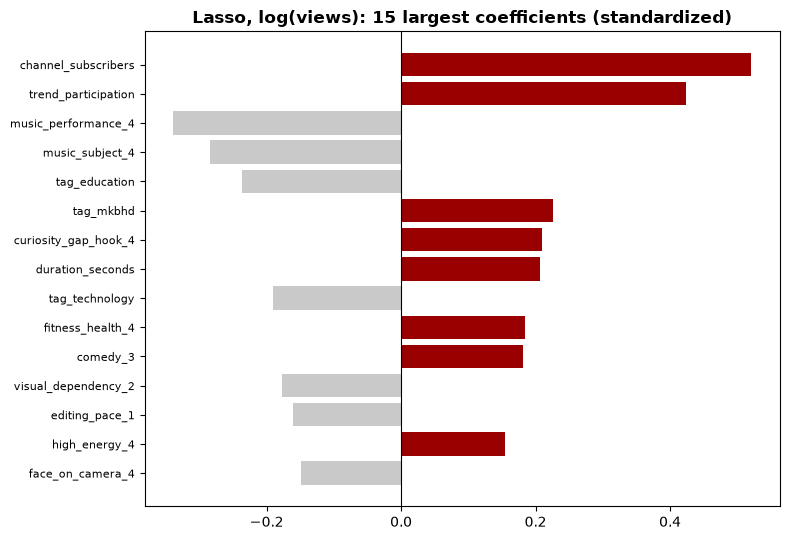

,feature,coef
306,channel_subscribers,0.520565
300,trend_participation,0.424188
91,music_performance_4,-0.338577
259,music_subject_4,-0.283565
369,tag_education,-0.236512
...,...,...
12,reaction_1,0.002828
202,music_sound_design_3,0.002735
96,podcast_long_form_conversation_1,-0.001938
232,direct_address_1,-0.001911


In [8]:
"""Coefficients below 1e-8 in size are numerical zeros from the solver. Standardized coefficients: change in log(1 + views) per 1 SD of the column, holding the others fixed. Correlational."""
df_coef = pd.DataFrame({"feature": feature_cols, "coef": lasso_models["log_views"][-1].coef_})
df_kept = df_coef[df_coef["coef"].abs() > 1e-8].sort_values("coef", key=abs, ascending=False)
print(f"log_views: kept {len(df_kept)} of {len(feature_cols)} columns")
df_top = df_kept.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(df_top["feature"], df_top["coef"], color=[RED if coef > 0 else GRAY for coef in df_top["coef"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Lasso, log(views): 15 largest coefficients (standardized)", fontweight="bold")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
df_kept

## What Lasso kept: log(likes)

In [9]:
df_coef_likes = pd.DataFrame({"feature": feature_cols, "coef": lasso_models["log_likes"][-1].coef_})
df_kept_likes = df_coef_likes[df_coef_likes["coef"].abs() > 1e-8].sort_values("coef", key=abs, ascending=False)
print(f"log_likes: kept {len(df_kept_likes)} of {len(feature_cols)} columns")
df_kept_likes

log_likes: kept 125 of 372 columns


,feature,coef
306,channel_subscribers,0.458050
300,trend_participation,0.438320
91,music_performance_4,-0.397925
305,age_days_at_pull,0.303841
369,tag_education,-0.258040
...,...,...
82,skit_3,0.001522
256,music_subject_1,-0.001260
184,visual_dependency_1,-0.000784
277,news_politics_2,-0.000588


## Save results

In [10]:
output_dir = os.path.dirname(config.MODEL_MATRIX_PATH)
df_lasso.to_csv(os.path.join(output_dir, "lasso_results.csv"), index=False)
df_path.to_csv(os.path.join(output_dir, "lasso_path.csv"), index=False)
pd.concat([df_kept.assign(target="log_views"), df_kept_likes.assign(target="log_likes")]).to_csv(os.path.join(output_dir, "lasso_coefficients.csv"), index=False)
print("saved to", output_dir)

saved to /Users/leoyang/Downloads/Github Repos/DSO_585_project/data/processed
